# 01 — Dataset Analysis, EDA & Data Preparation

**Project:** Real vs AI-Generated Image Classification Using CNN  
**Dataset:** `Rajarshi-Roy-research/Defactify_Image_Dataset`  
**Purpose:** memahami dataset, melakukan audit, mempertahankan official split, menyiapkan manifest dan konfigurasi untuk Model A (Custom CNN) dan Model B (MobileNetV2).

## Scope notebook

Notebook ini menyiapkan **metadata dan referensi data** untuk training. Notebook ini tidak mengekspor 96.000 gambar menjadi file baru agar tidak membuat salinan dataset berukuran besar.

Output akhirnya berupa ZIP yang berisi CSV manifest, JSON konfigurasi, dan laporan audit. Unduh ZIP tersebut lalu pindahkan isinya secara manual ke folder `artifacts/` pada repository GitHub.

**Prinsip penting:**
- Inspeksi test set untuk memahami struktur dan melaporkan statistik bukan otomatis data leakage.
- Model dan keputusan tuning tidak boleh menggunakan test set. Test set hanya untuk evaluasi akhir.
- Caption overlap akan dilaporkan sebagai *potential group overlap*. Caption sama belum membuktikan bahwa gambar sumbernya identik, karena dataset card tidak menyediakan source-image ID.
- Official train/validation/test split dipertahankan pada versi awal ini. Jangan membuat split baru secara otomatis sebelum tim menyepakati protokol eksperimennya.
- Normalisasi khusus model dan augmentation akan ditentukan di notebook model masing-masing.

## 1. Environment Setup

Bagian ini menyiapkan library dan lokasi cache. Cache diarahkan ke folder Google Drive yang sama dengan notebook sebelumnya (`MyDrive/dataset_huggingface`) agar cache yang sudah ada bisa digunakan kembali ketika runtime Colab terputus.

In [1]:
# Jalankan hanya jika library belum tersedia atau import berikut gagal.
# %pip -q install -U datasets pandas numpy matplotlib seaborn pillow tqdm

import os
import json
import hashlib
import zipfile
from datetime import datetime, timezone
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")
SEED = 42
rng = np.random.default_rng(SEED)

print("Environment ready")

Environment ready


In [2]:
# Google Colab + Google Drive
from google.colab import drive

drive.mount("/content/drive")

PROJECT_CACHE_DIR = Path("/content/drive/MyDrive/dataset_huggingface")
PROJECT_CACHE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = Path("/content/defactify_preparation_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset cache:", PROJECT_CACHE_DIR)
print("Artifact output:", OUTPUT_DIR)

Mounted at /content/drive
Dataset cache: /content/drive/MyDrive/dataset_huggingface
Artifact output: /content/defactify_preparation_artifacts


## 2. Project Configuration

Konfigurasi utama disimpan di satu cell supaya mudah diubah. `IMAGE_SIZE` adalah ukuran target yang akan dipakai saat model membaca gambar, **bukan klaim bahwa semua gambar sumber sudah berukuran 224 × 224**.

Untuk menjaga konsistensi antar-notebook, semua anggota harus memakai dataset ID, revision, label mapping, dan manifest yang sama.

In [3]:
DATASET_ID = "Rajarshi-Roy-research/Defactify_Image_Dataset"
DATASET_REVISION_REQUESTED = "main"  # Branch yang akan di-resolve menjadi commit SHA.
DATASET_REVISION = DATASET_REVISION_REQUESTED

IMAGE_SIZE = (224, 224)
COLOR_MODE = "RGB"
RESIZE_INTERPOLATION = "bilinear"

# Ukuran sampel untuk analisis resolusi dan pemeriksaan decode.
# Naikkan jika ingin audit yang lebih menyeluruh.
RESOLUTION_SAMPLE_PER_SPLIT = 500
IMAGE_DECODE_AUDIT_PER_SPLIT = 300
RUN_FULL_IMAGE_DECODE_AUDIT = False  # True akan memeriksa seluruh 96.000 gambar dan lebih lama.

LABEL_A_MAPPING = {
    0: "Real",
    1: "AI-Generated",
}

LABEL_B_MAPPING = {
    0: "Real",
    1: "Stable Diffusion 2.1",
    2: "Stable Diffusion XL (SDXL)",
    3: "Stable Diffusion 3",
    4: "DALL-E 3",
    5: "Midjourney v6",
}

SPLIT_NAMES = ["train", "validation", "test"]

print("Configuration loaded")
print("Dataset:", DATASET_ID)
print("Revision:", DATASET_REVISION)
print("Target image size:", IMAGE_SIZE)

Configuration loaded
Dataset: Rajarshi-Roy-research/Defactify_Image_Dataset
Revision: main
Target image size: (224, 224)


## 3. Load Dataset

`load_dataset()` menggunakan cache Hugging Face. Jika dataset yang sama sudah tersedia di lokasi cache, library biasanya akan menggunakan cache dan tidak mengunduh ulang semua data.

**Jangan** menghapus folder cache atau menggunakan `download_mode="force_redownload"` kecuali memang ingin mengunduh ulang.

In [4]:
from datasets import load_dataset
from huggingface_hub import HfApi

# Resolve the mutable branch name to an immutable commit SHA for reproducibility.
try:
    DATASET_REVISION = HfApi().dataset_info(
        repo_id=DATASET_ID,
        revision=DATASET_REVISION_REQUESTED,
    ).sha
    print("Resolved dataset commit:", DATASET_REVISION)
except Exception as exc:
    print("Could not resolve commit SHA; fallback to requested revision:", exc)
    DATASET_REVISION = DATASET_REVISION_REQUESTED

ds = load_dataset(
    DATASET_ID,
    revision=DATASET_REVISION,
    cache_dir=str(PROJECT_CACHE_DIR),
    download_mode="reuse_dataset_if_exists",
)

print(ds)

Resolved dataset commit: 1c3b714c9691eb6dd11c2c1e92eab1ac29584fa0


README.md:   0%|          | 0.00/5.37k [00:00<?, ?B/s]

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  333MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  345MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (30 outputs left out)

Generating validation split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/42000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/45000 [00:00<?, ? examples/s]

DatasetDict({
    validation: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 9000
    })
    train: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 42000
    })
    test: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 45000
    })
})


In [5]:
# Validasi struktur dasar agar error terdeteksi sejak awal.
required_columns = {"Caption", "Image", "Label_A", "Label_B"}

assert set(SPLIT_NAMES).issubset(set(ds.keys())), f"Split tidak lengkap: {list(ds.keys())}"

for split_name in SPLIT_NAMES:
    available_columns = set(ds[split_name].column_names)
    missing_columns = required_columns - available_columns
    assert not missing_columns, f"Kolom hilang pada {split_name}: {missing_columns}"

print("Dataset structure validated")
for split_name in SPLIT_NAMES:
    print(f"{split_name}: {len(ds[split_name]):,} rows")

Dataset structure validated
train: 42,000 rows
validation: 9,000 rows
test: 45,000 rows


## 4. Dataset Overview

Bagian ini merangkum jumlah baris, kolom, dan tipe fitur. Jumlah split di sini mengikuti dataset yang dimuat, bukan angka yang diketik manual.

In [6]:
print("TRAIN FEATURES")
print(ds["train"].features)

split_overview = pd.DataFrame([
    {
        "split": split_name,
        "rows": len(ds[split_name]),
        "columns": ", ".join(ds[split_name].column_names),
    }
    for split_name in SPLIT_NAMES
])

display(split_overview)

TRAIN FEATURES
{'Caption': Value('string'), 'Image': Image(mode=None, decode=True), 'Label_A': Value('int32'), 'Label_B': Value('int32')}


,split,rows,columns
0,train,42000,"Caption, Image, Label_A, Label_B"
1,validation,9000,"Caption, Image, Label_A, Label_B"
2,test,45000,"Caption, Image, Label_A, Label_B"


## 5. Label Mapping & Class Distribution

Dataset card mendefinisikan `Label_A` untuk Task A (Real vs AI-Generated) dan `Label_B` untuk sumber gambar. Kita menggunakan `Label_A` sebagai target utama klasifikasi.

`Label_B` hanya digunakan sebagai metadata untuk analisis performa berdasarkan generator; jangan masukkan `Label_B` sebagai input model Task A.

In [7]:
# Pastikan nilai label aktual sesuai dengan mapping yang kita pakai.
for split_name in SPLIT_NAMES:
    labels_a = set(ds[split_name]["Label_A"])
    labels_b = set(ds[split_name]["Label_B"])
    assert labels_a.issubset(set(LABEL_A_MAPPING)), f"Label_A tidak dikenal di {split_name}: {labels_a}"
    assert labels_b.issubset(set(LABEL_B_MAPPING)), f"Label_B tidak dikenal di {split_name}: {labels_b}"

print("Label mappings validated")

Label mappings validated


In [8]:
# Distribusi Label_A per split
class_rows = []
for split_name in SPLIT_NAMES:
    counts = Counter(ds[split_name]["Label_A"])
    total = len(ds[split_name])
    for label_id, label_name in LABEL_A_MAPPING.items():
        count = counts.get(label_id, 0)
        class_rows.append({
            "split": split_name,
            "label_id": label_id,
            "class_name": label_name,
            "count": count,
            "percentage": 100 * count / total if total else 0,
        })

class_distribution = pd.DataFrame(class_rows)
display(class_distribution)

,split,label_id,class_name,count,percentage
0,train,0,Real,7000,16.666667
1,train,1,AI-Generated,35000,83.333333
2,validation,0,Real,1500,16.666667
3,validation,1,AI-Generated,7500,83.333333
4,test,0,Real,7500,16.666667
5,test,1,AI-Generated,37500,83.333333


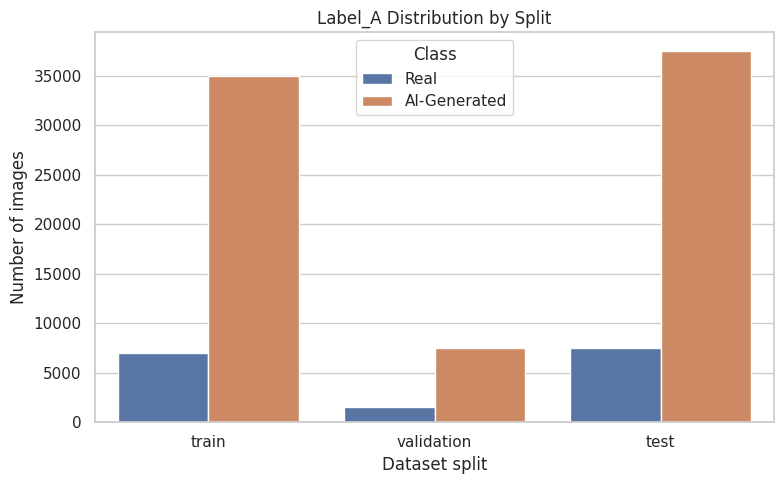

In [9]:
plt.figure(figsize=(8, 5))
sns.barplot(data=class_distribution, x="split", y="count", hue="class_name")
plt.title("Label_A Distribution by Split")
plt.xlabel("Dataset split")
plt.ylabel("Number of images")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [10]:
# Distribusi Label_B per split
source_rows = []
for split_name in SPLIT_NAMES:
    counts = Counter(ds[split_name]["Label_B"])
    total = len(ds[split_name])
    for label_id, label_name in LABEL_B_MAPPING.items():
        count = counts.get(label_id, 0)
        source_rows.append({
            "split": split_name,
            "label_b_id": label_id,
            "source_name": label_name,
            "count": count,
            "percentage": 100 * count / total if total else 0,
        })

source_distribution = pd.DataFrame(source_rows)
display(source_distribution)

,split,label_b_id,source_name,count,percentage
0,train,0,Real,7000,16.666667
1,train,1,Stable Diffusion 2.1,7000,16.666667
2,train,2,Stable Diffusion XL (SDXL),7000,16.666667
3,train,3,Stable Diffusion 3,7000,16.666667
4,train,4,DALL-E 3,7000,16.666667
5,train,5,Midjourney v6,7000,16.666667
6,validation,0,Real,1500,16.666667
7,validation,1,Stable Diffusion 2.1,1500,16.666667
8,validation,2,Stable Diffusion XL (SDXL),1500,16.666667
9,validation,3,Stable Diffusion 3,1500,16.666667


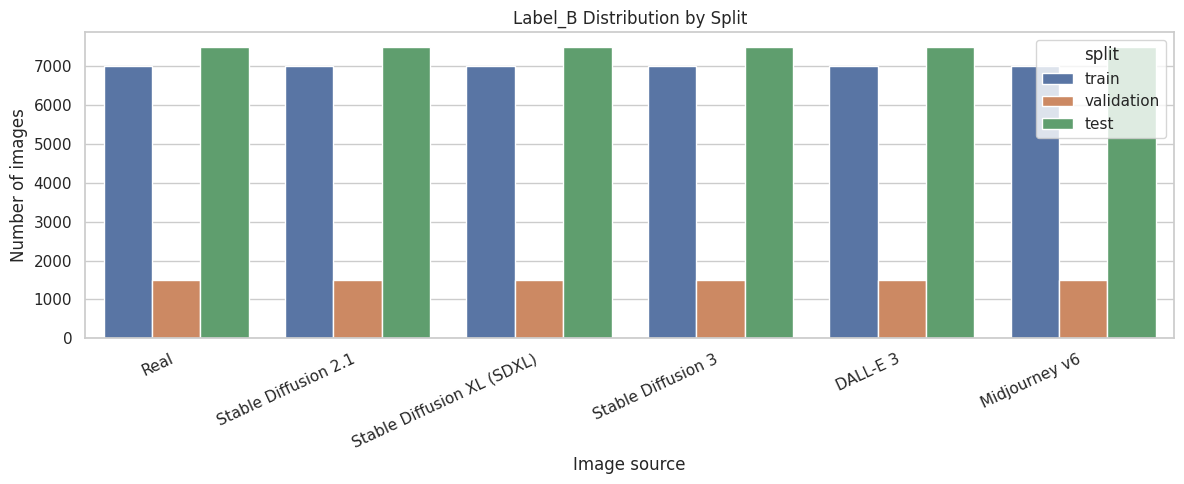

In [11]:
plt.figure(figsize=(12, 5))
sns.barplot(data=source_distribution, x="source_name", y="count", hue="split")
plt.title("Label_B Distribution by Split")
plt.xlabel("Image source")
plt.ylabel("Number of images")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 6. Visual Inspection of Image Samples

Tampilkan satu contoh gambar untuk setiap nilai `Label_B` dari split train. Tujuannya adalah memeriksa apakah gambar dapat dibaca dan memahami variasi visual setiap sumber.

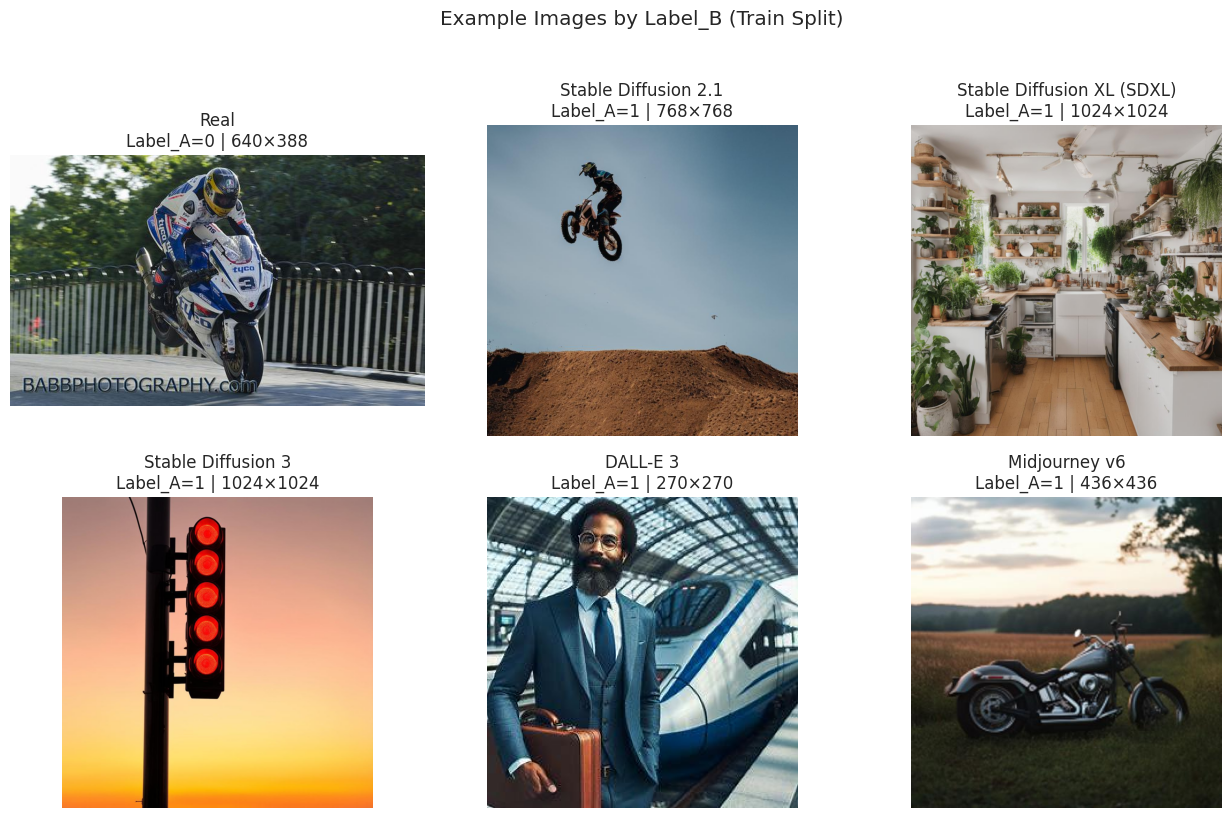

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for label_id, label_name in LABEL_B_MAPPING.items():
    candidate_indices = [
        idx for idx, value in enumerate(ds["train"]["Label_B"])
        if value == label_id
    ]
    if not candidate_indices:
        axes[label_id].set_title(f"{label_name} (no sample)")
        axes[label_id].axis("off")
        continue

    selected_idx = int(rng.choice(candidate_indices))
    sample = ds["train"][selected_idx]
    image = sample["Image"].convert("RGB")

    axes[label_id].imshow(image)
    axes[label_id].set_title(
        f"{label_name}\nLabel_A={sample['Label_A']} | {image.size[0]}×{image.size[1]}"
    )
    axes[label_id].axis("off")

plt.suptitle("Example Images by Label_B (Train Split)", y=1.02)
plt.tight_layout()
plt.show()

## 7. Image Resolution Analysis

Dataset card tidak memberikan satu ukuran resolusi untuk semua gambar. Karena itu, kita mengukur resolusi aktual dari sampel acak pada setiap split.

Hasil ini adalah **sample-based analysis**, bukan pemeriksaan seluruh gambar. Ukuran target saat training tetap ditetapkan pada 224 × 224 agar sesuai dengan rancangan awal kedua model.

In [13]:
resolution_records = []
for split_name in SPLIT_NAMES:
    n_rows = len(ds[split_name])
    n_sample = min(RESOLUTION_SAMPLE_PER_SPLIT, n_rows)
    sampled_indices = rng.choice(n_rows, size=n_sample, replace=False)

    for idx in tqdm(sampled_indices, desc=f"Sampling resolution: {split_name}"):
        image = ds[split_name][int(idx)]["Image"]
        width, height = image.size
        resolution_records.append({
            "split": split_name,
            "row_idx": int(idx),
            "width": width,
            "height": height,
            "resolution": f"{width}x{height}",
            "aspect_ratio": width / height if height else np.nan,
            "mode": image.mode,
        })

resolution_sample = pd.DataFrame(resolution_records)
print("Resolution sample rows:", len(resolution_sample))
display(resolution_sample.head())

Sampling resolution: train:   0%|          | 0/500 [00:00<?, ?it/s]

Sampling resolution: validation:   0%|          | 0/500 [00:00<?, ?it/s]

Sampling resolution: test:   0%|          | 0/500 [00:00<?, ?it/s]

Resolution sample rows: 1500


,split,row_idx,width,height,resolution,aspect_ratio,mode
0,train,29117,436,436,436x436,1.0,RGB
1,train,11355,1024,1024,1024x1024,1.0,RGB
2,train,35273,436,436,436x436,1.0,RGB
3,train,23206,270,270,270x270,1.0,RGB
4,train,25442,1024,1024,1024x1024,1.0,RGB


In [14]:
resolution_summary = (
    resolution_sample.groupby("split")
    .agg(
        sampled_images=("row_idx", "count"),
        unique_resolutions=("resolution", "nunique"),
        median_width=("width", "median"),
        median_height=("height", "median"),
        min_width=("width", "min"),
        max_width=("width", "max"),
        min_height=("height", "min"),
        max_height=("height", "max"),
    )
    .reset_index()
)
display(resolution_summary)

,split,sampled_images,unique_resolutions,median_width,median_height,min_width,max_width,min_height,max_height
0,test,500,46,640.0,640.0,270,1024,267,1024
1,train,500,49,640.0,500.0,270,1024,213,1024
2,validation,500,39,640.0,640.0,270,1024,239,1024


## 8. Metadata & Image Quality Audit

Pemeriksaan metadata dilakukan terhadap seluruh baris. Pemeriksaan decode gambar secara default menggunakan sampel agar runtime tidak terlalu lama. Jika ingin memeriksa semua gambar, ubah `RUN_FULL_IMAGE_DECODE_AUDIT = True` pada bagian konfigurasi.

Catatan: audit ini memeriksa apakah objek gambar dapat dibuka dan dimuat. Hasil nol error pada sampel bukan bukti matematis bahwa semua file pasti valid; error tetap ditangani saat data loader training dibuat.

In [15]:
metadata_audit_rows = []
for split_name in SPLIT_NAMES:
    split_ds = ds[split_name]
    captions = split_ds["Caption"]
    labels_a = split_ds["Label_A"]
    labels_b = split_ds["Label_B"]

    metadata_audit_rows.append({
        "split": split_name,
        "rows": len(split_ds),
        "missing_caption": sum(value is None or str(value).strip() == "" for value in captions),
        "missing_label_a": sum(value is None for value in labels_a),
        "missing_label_b": sum(value is None for value in labels_b),
    })

metadata_audit = pd.DataFrame(metadata_audit_rows)
display(metadata_audit)

,split,rows,missing_caption,missing_label_a,missing_label_b
0,train,42000,0,0,0
1,validation,9000,0,0,0
2,test,45000,0,0,0


In [16]:
image_audit_rows = []
all_image_audit_errors = []
for split_name in SPLIT_NAMES:
    n_rows = len(ds[split_name])
    if RUN_FULL_IMAGE_DECODE_AUDIT:
        indices = range(n_rows)
        audit_mode = "full"
    else:
        n_sample = min(IMAGE_DECODE_AUDIT_PER_SPLIT, n_rows)
        indices = rng.choice(n_rows, size=n_sample, replace=False)
        audit_mode = "sample"

    checked = 0
    split_errors = []
    for idx in tqdm(indices, desc=f"Image decode audit: {split_name}"):
        try:
            image = ds[split_name][int(idx)]["Image"]
            if image is None:
                raise ValueError("Image is None")
            image.convert("RGB").load()
            checked += 1
        except Exception as exc:
            split_errors.append({"split": split_name, "row_idx": int(idx), "error": str(exc)[:250]})

    image_audit_rows.append({
        "split": split_name,
        "audit_mode": audit_mode,
        "images_checked": checked + len(split_errors),
        "decode_errors": len(split_errors),
    })
    all_image_audit_errors.extend(split_errors)

image_audit = pd.DataFrame(image_audit_rows)
display(image_audit)

image_audit_errors = pd.DataFrame(all_image_audit_errors, columns=["split", "row_idx", "error"])

Image decode audit: train:   0%|          | 0/300 [00:00<?, ?it/s]

Image decode audit: validation:   0%|          | 0/300 [00:00<?, ?it/s]

Image decode audit: test:   0%|          | 0/300 [00:00<?, ?it/s]

,split,audit_mode,images_checked,decode_errors
0,train,sample,300,0
1,validation,sample,300,0
2,test,sample,300,0


## 9. Caption Group Overlap Audit

Bagian ini bertujuan untuk memeriksa apakah teks caption yang sama muncul pada beberapa bagian dataset, yaitu training, validation, dan testing.

Pemeriksaan dilakukan dengan menormalisasi teks caption terlebih dahulu, sehingga perbedaan huruf besar, huruf kecil, dan spasi tidak dianggap sebagai perbedaan caption.

**Hal-hal yang perlu diperhatikan:**

- Caption yang sama tidak otomatis menunjukkan bahwa gambar yang digunakan merupakan gambar sumber yang sama.
- Satu teks caption dapat digunakan untuk mendeskripsikan beberapa gambar asli yang berbeda.
- Meskipun demikian, caption yang muncul pada beberapa bagian dataset dapat menjadi indikasi adanya hubungan antara sampel yang perlu diperhatikan.
- Pemeriksaan ini hanya digunakan untuk memahami dan mendokumentasikan struktur dataset. Tidak ada gambar yang otomatis dihapus atau dipindahkan.

Untuk eksperimen awal, kita akan tetap menggunakan pembagian dataset resmi dari penyedia dataset. Hasil pemeriksaan tumpang tindih caption akan dicatat sebagai salah satu keterbatasan dataset.

Data testing tetap disimpan untuk evaluasi akhir model dan tidak digunakan untuk memilih arsitektur maupun melakukan hyperparameter tuning.

In [29]:
def normalize_caption(text):
    """
    Menyeragamkan format teks caption
    untuk pemeriksaan tumpang tindih.
    """
    if text is None or pd.isna(text):
        return ""

    return " ".join(str(text).casefold().split())


caption_rows = []

for split_name in SPLIT_NAMES:

    split_ds = ds[split_name]

    for idx, (caption, label_a, label_b) in enumerate(
        zip(
            split_ds["Caption"],
            split_ds["Label_A"],
            split_ds["Label_B"]
        )
    ):

        normalized = normalize_caption(caption)

        if not normalized:
            continue

        caption_rows.append({
            "split": split_name,
            "row_idx": idx,
            "caption_normalized": normalized,
            "label_a": int(label_a),
            "label_b": int(label_b)
        })


caption_index_df = pd.DataFrame(caption_rows)

print("Total data caption:", len(caption_index_df))

display(caption_index_df.head())

Total data caption: 96000


,split,row_idx,caption_normalized,label_a,label_b
0,train,0,two tall giraffe standing next to each other o...,0,0
1,train,1,two tall giraffe standing next to each other o...,1,1
2,train,2,two tall giraffe standing next to each other o...,1,2
3,train,3,two tall giraffe standing next to each other o...,1,3
4,train,4,two tall giraffe standing next to each other o...,1,4


In [30]:
# Menghitung jumlah kemunculan setiap caption
# pada masing-masing split.
caption_split_counts = (
    caption_index_df
    .groupby(["caption_normalized", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SPLIT_NAMES, fill_value=0)
)

# Menandai apakah suatu caption muncul pada setiap split.
caption_presence = caption_split_counts.gt(0)

# Menentukan pasangan split yang akan dibandingkan.
pair_definitions = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

overlap_summary_rows = []

for split_a, split_b in pair_definitions:

    overlap_count = int(
        (
            caption_presence[split_a]
            & caption_presence[split_b]
        ).sum()
    )

    overlap_summary_rows.append({
        "split_a": split_a,
        "split_b": split_b,
        "overlapping_unique_captions": overlap_count
    })


overlap_summary = pd.DataFrame(overlap_summary_rows)

display(overlap_summary)

,split_a,split_b,overlapping_unique_captions
0,train,validation,26
1,train,test,34
2,validation,test,8


In [31]:
def audit_caption_composition(split_ds, split_name):

    df = pd.DataFrame({
        "caption": split_ds["Caption"],
        "label_a": split_ds["Label_A"],
        "label_b": split_ds["Label_B"]
    })

    # Menyeragamkan caption sebelum pengelompokan.
    df["caption_normalized"] = (
        df["caption"].map(normalize_caption)
    )

    df = df[df["caption_normalized"] != ""]

    # Menghitung jumlah kemunculan setiap Label_B
    # untuk masing-masing caption.
    counts = pd.crosstab(
        df["caption_normalized"],
        df["label_b"]
    ).reindex(
        columns=range(6),
        fill_value=0
    )

    # Memeriksa apakah jumlah kemunculan keenam kategori
    # Label_B sama untuk setiap caption.
    equal_counts = (
        counts.nunique(axis=1).eq(1)
        & counts.sum(axis=1).gt(0)
    )

    # Memeriksa konsistensi hubungan Label_A dan Label_B.
    expected_label_a = np.where(
        df["label_b"] == 0,
        0,
        1
    )

    label_consistent = np.array_equal(
        df["label_a"].to_numpy(),
        expected_label_a
    )

    return {
        "split": split_name,
        "unique_normalized_captions": len(counts),
        "captions_with_equal_label_b_counts": int(
            equal_counts.sum()
        ),
        "captions_with_unequal_label_b_counts": int(
            (~equal_counts).sum()
        ),
        "label_mapping_consistent": label_consistent
    }


composition_results = pd.DataFrame([
    audit_caption_composition(ds[split_name], split_name)
    for split_name in SPLIT_NAMES
])

display(composition_results)

,split,unique_normalized_captions,captions_with_equal_label_b_counts,captions_with_unequal_label_b_counts,label_mapping_consistent
0,train,6944,6944,0,True
1,validation,1495,1495,0,True
2,test,1500,1500,0,True


### Interpretasi Hasil dan Keputusan Pembagian Dataset

Berdasarkan hasil pemeriksaan, ditemukan beberapa teks caption yang muncul pada lebih dari satu bagian dataset, yaitu training, validation, dan testing.

Dari hasil eksekusi sebelumnya, diperoleh:

| Perbandingan | Caption overlap |
|---|---:|
| Train dan Validation | 26 |
| Train dan Test | 34 |
| Validation dan Test | 8 |

Hasil tersebut menunjukkan adanya caption yang sama pada beberapa split. Namun, kondisi tersebut tidak secara otomatis membuktikan terjadinya kebocoran data (*data leakage*), karena satu caption dapat digunakan untuk mendeskripsikan beberapa gambar asli yang berbeda.

Pemeriksaan komposisi `Label_B` juga menunjukkan bahwa caption yang ditemukan pada masing-masing split memiliki jumlah kemunculan yang seimbang pada keenam kategori sumber gambar. Hasil ini menggambarkan komposisi metadata, tetapi tidak membuktikan bahwa gambar-gambar tersebut memiliki identitas sumber yang sama.

**Keputusan pembagian dataset:**

1. Tetap menggunakan official train, validation, dan test splits dari penyedia dataset.
2. Tidak menghapus atau memindahkan sampel hanya berdasarkan kesamaan caption.
3. Mendokumentasikan hasil caption overlap sebagai salah satu keterbatasan dataset.
4. Menggunakan validation set untuk pemilihan model dan hyperparameter tuning.
5. Menyimpan test set untuk evaluasi akhir setelah model selesai dikembangkan.

Untuk penelitian lanjutan yang ingin menguji generalisasi terhadap gambar sumber yang benar-benar belum pernah dilihat, diperlukan identitas gambar sumber atau pemeriksaan kesamaan gambar yang lebih mendalam.

## 10. Build Training Manifests

Manifest CSV tidak menyimpan file gambar. Manifest menyimpan `source_split` dan `row_idx` agar notebook model dapat mengambil kembali baris yang tepat dari dataset Hugging Face.

**Penting:** notebook model harus memuat dataset yang sama (dataset ID dan revision yang sama). Jangan menggunakan manifest ini dengan versi dataset yang berbeda karena `row_idx` dapat menunjuk ke sampel yang berbeda.

In [20]:
def make_caption_group_id(caption):
    normalized = normalize_caption(caption)
    return hashlib.sha1(normalized.encode("utf-8")).hexdigest()[:16] if normalized else "missing_caption"

manifests = {}
for split_name in SPLIT_NAMES:
    split_ds = ds[split_name]
    captions = split_ds["Caption"]
    labels_a = split_ds["Label_A"]
    labels_b = split_ds["Label_B"]

    manifest_df = pd.DataFrame({
        "image_id": [f"{split_name}_{idx:06d}" for idx in range(len(split_ds))],
        "source_split": split_name,
        "row_idx": np.arange(len(split_ds), dtype=int),
        "caption_group_id": [make_caption_group_id(caption) for caption in captions],
        "caption": captions,
        "label_a": [int(value) for value in labels_a],
        "label_a_name": [LABEL_A_MAPPING[int(value)] for value in labels_a],
        "label_b": [int(value) for value in labels_b],
        "label_b_name": [LABEL_B_MAPPING[int(value)] for value in labels_b],
    })
    manifests[split_name] = manifest_df

    print(f"{split_name}: {len(manifest_df):,} manifest rows")
    display(manifest_df.head(3))

train: 42,000 manifest rows


,image_id,source_split,row_idx,caption_group_id,caption,label_a,label_a_name,label_b,label_b_name
0,train_000000,train,0,6dfa76b111164685,Two tall giraffe standing next to each other o...,0,Real,0,Real
1,train_000001,train,1,6dfa76b111164685,Two tall giraffe standing next to each other o...,1,AI-Generated,1,Stable Diffusion 2.1
2,train_000002,train,2,6dfa76b111164685,Two tall giraffe standing next to each other o...,1,AI-Generated,2,Stable Diffusion XL (SDXL)


validation: 9,000 manifest rows


,image_id,source_split,row_idx,caption_group_id,caption,label_a,label_a_name,label_b,label_b_name
0,validation_000000,validation,0,73521ada7d3e178a,a toilet sits next to a shower an sink,1,AI-Generated,3,Stable Diffusion 3
1,validation_000001,validation,1,1157c77033ba1e91,A TV sitting on top of a table next to a lapto...,0,Real,0,Real
2,validation_000002,validation,2,3e83f12ba01c9503,Two giraffes eat from a pot attached to a fence.,1,AI-Generated,1,Stable Diffusion 2.1


test: 45,000 manifest rows


,image_id,source_split,row_idx,caption_group_id,caption,label_a,label_a_name,label_b,label_b_name
0,test_000000,test,0,553de08770b372f6,School buses parked along the curb of a city s...,1,AI-Generated,5,Midjourney v6
1,test_000001,test,1,00cc4e40bbfc377c,A distant airplane high up into the sky.,0,Real,0,Real
2,test_000002,test,2,baf6a0538ec7884c,A herd of cattle laying in the grass on the gr...,1,AI-Generated,1,Stable Diffusion 2.1


## 11. Shared Preprocessing Configuration

Bagian ini hanya mendefinisikan standar bersama: RGB dan ukuran target gambar. Notebook ini belum mengubah atau menyimpan semua gambar menjadi tensor.

Normalisasi dan augmentation ditentukan di notebook model masing-masing:
- Custom CNN: tentukan skala input sesuai implementasi model.
- MobileNetV2: gunakan preprocessing resmi yang sesuai dengan framework dan pretrained weights yang dipilih.
- Augmentation hanya diterapkan pada training data, bukan validation/test.

In [21]:
label_mapping = {
    "target_column": "Label_A",
    "target_task": "Real vs AI-Generated image classification",
    "Label_A": {str(k): v for k, v in LABEL_A_MAPPING.items()},
    "Label_B": {str(k): v for k, v in LABEL_B_MAPPING.items()},
}

preprocessing_config = {
    "shared_image_input": {
        "image_size": list(IMAGE_SIZE),
        "color_mode": COLOR_MODE,
        "resize_interpolation": RESIZE_INTERPOLATION,
        "channels": 3,
    },
    "model_specific_processing": {
        "custom_cnn": "Define normalization in the Custom CNN notebook.",
        "mobilenetv2": "Use the official preprocessing function for the selected framework and pretrained weights.",
    },
    "augmentation": {
        "applied_in_this_notebook": False,
        "policy": "Define training-only augmentation in each model notebook; do not augment validation/test.",
    },
    "note": "This config describes the shared preprocessing contract. It does not mean images have already been resized or normalized on disk.",
}

print(json.dumps(preprocessing_config, indent=2))

{
  "shared_image_input": {
    "image_size": [
      224,
      224
    ],
    "color_mode": "RGB",
    "resize_interpolation": "bilinear",
    "channels": 3
  },
  "model_specific_processing": {
    "custom_cnn": "Define normalization in the Custom CNN notebook.",
    "mobilenetv2": "Use the official preprocessing function for the selected framework and pretrained weights."
  },
  "augmentation": {
    "applied_in_this_notebook": false,
    "policy": "Define training-only augmentation in each model notebook; do not augment validation/test."
  },
  "note": "This config describes the shared preprocessing contract. It does not mean images have already been resized or normalized on disk."
}


## 12. Create Dataset Manifest & Audit Reports

Manifest akhir mencatat sumber dataset, ukuran split aktual, pemetaan label, image size target, dan ringkasan caption overlap. Jumlah pada manifest dihitung dari dataset yang benar-benar dimuat.

In [22]:
class_distribution_records = {}
for split_name in SPLIT_NAMES:
    counts = Counter(ds[split_name]["Label_A"])
    class_distribution_records[split_name] = {
        LABEL_A_MAPPING[label_id]: int(counts.get(label_id, 0))
        for label_id in LABEL_A_MAPPING
    }

source_distribution_records = {}
for split_name in SPLIT_NAMES:
    counts = Counter(ds[split_name]["Label_B"])
    source_distribution_records[split_name] = {
        LABEL_B_MAPPING[label_id]: int(counts.get(label_id, 0))
        for label_id in LABEL_B_MAPPING
    }

manifest = {
    "project_name": "Real vs AI-Generated Image Classification",
    "dataset_id": DATASET_ID,
    "dataset_revision": DATASET_REVISION,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "target_column": "Label_A",
    "official_source_split_counts": {split: int(len(ds[split])) for split in SPLIT_NAMES},
    "label_mapping": label_mapping,
    "label_a_distribution": class_distribution_records,
    "label_b_distribution": source_distribution_records,
    "target_image_size": list(IMAGE_SIZE),
    "caption_overlap_audit": overlap_summary.to_dict(orient="records"),
    "split_policy": "Official dataset splits retained; caption overlap is reported, not automatically reassigned.",
    "image_rows_are_not_exported": True,
}

print(json.dumps(manifest, indent=2)[:5000])

{
  "project_name": "Real vs AI-Generated Image Classification",
  "dataset_id": "Rajarshi-Roy-research/Defactify_Image_Dataset",
  "dataset_revision": "1c3b714c9691eb6dd11c2c1e92eab1ac29584fa0",
  "created_at_utc": "2026-11-05T04:44:06.796783+00:00",
  "target_column": "Label_A",
  "official_source_split_counts": {
    "train": 42000,
    "validation": 9000,
    "test": 45000
  },
  "label_mapping": {
    "target_column": "Label_A",
    "target_task": "Real vs AI-Generated image classification",
    "Label_A": {
      "0": "Real",
      "1": "AI-Generated"
    },
    "Label_B": {
      "0": "Real",
      "1": "Stable Diffusion 2.1",
      "2": "Stable Diffusion XL (SDXL)",
      "3": "Stable Diffusion 3",
      "4": "DALL-E 3",
      "5": "Midjourney v6"
    }
  },
  "label_a_distribution": {
    "train": {
      "Real": 7000,
      "AI-Generated": 35000
    },
    "validation": {
      "Real": 1500,
      "AI-Generated": 7500
    },
    "test": {
      "Real": 7500,
      "AI-Generat

## 13. Export Artifacts and Download

Cell berikut menyimpan file kecil yang diperlukan oleh anggota tim. Gambar tidak ikut dimasukkan ke ZIP, sehingga tidak perlu mengunduh ulang dataset 7.5 GB.

Setelah ZIP terunduh, ekstrak dan pindahkan isinya ke repository:
- CSV ke `artifacts/splits/`
- JSON ke `artifacts/configs/`
- laporan audit ke `artifacts/evaluation/` atau folder dokumentasi yang disepakati

In [23]:
# Buat struktur output lokal.
for folder in ["splits", "configs", "evaluation", "eda"]:
    (OUTPUT_DIR / folder).mkdir(parents=True, exist_ok=True)

# CSV manifests
for split_name, manifest_df in manifests.items():
    manifest_df.to_csv(OUTPUT_DIR / "splits" / f"{split_name}.csv", index=False)

# JSON configs/manifests
with open(OUTPUT_DIR / "configs" / "label_mapping.json", "w", encoding="utf-8") as f:
    json.dump(label_mapping, f, indent=4, ensure_ascii=False)

with open(OUTPUT_DIR / "configs" / "preprocessing_config.json", "w", encoding="utf-8") as f:
    json.dump(preprocessing_config, f, indent=4, ensure_ascii=False)

with open(OUTPUT_DIR / "configs" / "dataset_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=4, ensure_ascii=False)

# Audit and EDA tables
class_distribution.to_csv(OUTPUT_DIR / "eda" / "label_a_distribution.csv", index=False)
source_distribution.to_csv(OUTPUT_DIR / "eda" / "label_b_distribution.csv", index=False)
resolution_sample.to_csv(OUTPUT_DIR / "eda" / "resolution_sample.csv", index=False)
resolution_summary.to_csv(OUTPUT_DIR / "eda" / "resolution_summary.csv", index=False)
metadata_audit.to_csv(OUTPUT_DIR / "evaluation" / "metadata_audit.csv", index=False)
image_audit.to_csv(OUTPUT_DIR / "evaluation" / "image_decode_audit.csv", index=False)
image_audit_errors.to_csv(OUTPUT_DIR / "evaluation" / "image_decode_errors.csv", index=False)
overlap_summary.to_csv(OUTPUT_DIR / "evaluation" / "caption_overlap_summary.csv", index=False)
overlap_detail.to_csv(OUTPUT_DIR / "evaluation" / "caption_overlap_details.csv", index=False)

print("Artifacts exported to:", OUTPUT_DIR)

Artifacts exported to: /content/defactify_preparation_artifacts


In [24]:
# Buat ZIP untuk diunduh.
zip_path = Path("/content/data_preparation_artifacts.zip")

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    for file_path in OUTPUT_DIR.rglob("*"):
        if file_path.is_file():
            zipf.write(file_path, arcname=file_path.relative_to(OUTPUT_DIR))

size_mb = zip_path.stat().st_size / (1024 ** 2)
print(f"ZIP ready: {zip_path}")
print(f"ZIP size: {size_mb:.2f} MB")

ZIP ready: /content/data_preparation_artifacts.zip
ZIP size: 2.28 MB


In [25]:
# Otomatis mengunduh ZIP ke komputer dari Google Colab.
from google.colab import files
files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Handoff: How Model Notebooks Use the Manifests

Contoh berikut menunjukkan cara memilih baris dataset berdasarkan manifest. Jalankan di notebook Model A atau Model B setelah dataset dimuat dengan ID dan revision yang sama.

```python
import pandas as pd

train_manifest = pd.read_csv("artifacts/splits/train.csv")
train_indices = train_manifest["row_idx"].astype(int).tolist()

# ds harus merupakan dataset yang sama, dengan revision dan urutan baris yang sama.
train_subset = ds["train"].select(train_indices)

sample = train_subset[0]
image = sample["Image"].convert("RGB")
label = int(sample["Label_A"])
```

Model notebook kemudian menerapkan preprocessing framework-specific dan membuat data loader / `tf.data.Dataset` masing-masing. Untuk training, gunakan `Label_A` sebagai target. `Label_B` disimpan untuk analisis generator, bukan sebagai input model binary classification.

## 15. Final Readiness Checklist

Sebelum training dimulai, pastikan:
1. Dataset ID dan revision yang digunakan seluruh anggota sama.
2. File CSV manifest sudah berhasil diunduh dan dapat dibaca.
3. `row_idx` merujuk pada split sumber yang benar.
4. Caption overlap sudah didokumentasikan dan keputusan split disepakati tim.
5. Label_A mapping konsisten: 0 = Real, 1 = AI-Generated.
6. Preprocessing model-specific ditentukan di notebook masing-masing.
7. Augmentation hanya diterapkan ke training data.
8. Test set tidak digunakan untuk tuning atau pemilihan model.

**Notebook ini selesai pada tahap data handoff.** Training, model-specific normalization, augmentation, feature extraction, dan model fitting dilakukan di notebook Model A dan Model B.